In [1]:
import os
import urllib.request

MODEL_PATH = "pose_landmarker.task"

MODEL_URL = (
    "https://storage.googleapis.com/mediapipe-models/"
    "pose_landmarker/pose_landmarker_lite/"
    "float16/1/"
    "pose_landmarker_lite.task"
)

if not os.path.exists(MODEL_PATH):

    print("Downloading MediaPipe Pose Landmarker model...")

    urllib.request.urlretrieve(
        MODEL_URL,
        MODEL_PATH
    )

    print("Model downloaded successfully!")

else:

    print("Model already exists.")

print("Model path:", os.path.abspath(MODEL_PATH))

Model already exists.
Model path: /Users/jalshah/Desktop/Sem 5/Projects/YogaFlow/yoga_analyzer/pose_landmarker.task


In [2]:
import sys
import mediapipe as mp

print("Python:", sys.version)
print("MediaPipe:", mp.__version__)
print("MediaPipe location:", mp.__file__)

print("Tasks available:", hasattr(mp, "tasks"))

Python: 3.12.15 (main, Oct  1 2026, 20:49:34) [Clang 22.1.3 ]
MediaPipe: 0.10.21
MediaPipe location: /Users/jalshah/Desktop/Sem 5/Projects/YogaFlow/.venv312/lib/python3.12/site-packages/mediapipe/__init__.py
Tasks available: True


In [3]:
import mediapipe as mp

print("MediaPipe version:", mp.__version__)

BaseOptions = mp.tasks.BaseOptions
PoseLandmarker = mp.tasks.vision.PoseLandmarker
PoseLandmarkerOptions = mp.tasks.vision.PoseLandmarkerOptions
VisionRunningMode = mp.tasks.vision.RunningMode

options = PoseLandmarkerOptions(
    base_options=BaseOptions(
        model_asset_path=os.path.abspath(MODEL_PATH)
    ),
    running_mode=VisionRunningMode.IMAGE,
    num_poses=1,
    min_pose_detection_confidence=0.5,
    min_pose_presence_confidence=0.5,
    min_tracking_confidence=0.5
)

landmarker = PoseLandmarker.create_from_options(options)

print("Pose Landmarker loaded successfully!")

MediaPipe version: 0.10.21
Pose Landmarker loaded successfully!


I0000 00:00:1791041414.955290  171178 gl_context.cc:369] GL version: 2.1 (2.1 Metal - 91.7), renderer: Apple M2
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
W0000 00:00:1791041415.042361  171305 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1791041415.053812  171312 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


In [4]:
import cv2
import numpy as np
import pandas as pd
import os

DATASET_PATH = "/Users/jalshah/Desktop/SIH/YogaDataset"

data = []

# Supported image formats
IMAGE_EXTENSIONS = (
    ".jpg",
    ".jpeg",
    ".png",
    ".webp"
)

# Loop through each yoga pose folder
for pose_name in os.listdir(DATASET_PATH):

    pose_folder = os.path.join(
        DATASET_PATH,
        pose_name
    )

    # Ignore files
    if not os.path.isdir(pose_folder):
        continue

    print("Processing:", pose_name)

    # Loop through images
    for image_name in os.listdir(pose_folder):

        if not image_name.lower().endswith(IMAGE_EXTENSIONS):
            continue

        image_path = os.path.join(
            pose_folder,
            image_name
        )

        # Read image
        image = cv2.imread(image_path)

        if image is None:
            continue

        # BGR -> RGB
        rgb_image = cv2.cvtColor(
            image,
            cv2.COLOR_BGR2RGB
        )

        # MediaPipe image
        mp_image = mp.Image(
            image_format=mp.ImageFormat.SRGB,
            data=rgb_image
        )

        # Detect pose
        result = landmarker.detect(mp_image)

        # Make sure pose was detected
        if not result.pose_landmarks:
            print("No pose:", image_name)
            continue

        landmarks = result.pose_landmarks[0]

        # Store 33 landmarks
        row = {
            "pose": pose_name,
            "image": image_name
        }

        for i, landmark in enumerate(landmarks):

            row[f"x_{i}"] = landmark.x
            row[f"y_{i}"] = landmark.y
            row[f"z_{i}"] = landmark.z
            row[f"visibility_{i}"] = landmark.visibility

        data.append(row)


# Create dataframe
df = pd.DataFrame(data)

print()
print("Total images processed:", len(df))
print("Number of features:", len(df.columns))

df.head()

Processing: Navasana
No pose: File17.jpeg


W0000 00:00:1791041415.413502  171307 landmark_projection_calculator.cc:186] Using NORM_RECT without IMAGE_DIMENSIONS is only supported for the square ROI. Provide IMAGE_DIMENSIONS or use PROJECTION_MATRIX.


Processing: Hanumanasana
No pose: File38.jpeg
No pose: File14.png
Processing: Phalakasana
Processing: Ardha Navasana
No pose: File2.png
No pose: File8.png
No pose: File12.png
No pose: File7.jpeg
Processing: Adho Mukha Svanasana


libpng warning: cHRM: inconsistent chromaticities
libpng warning: iCCP: known incorrect sRGB profile
libpng warning: iCCP: known incorrect sRGB profile


No pose: File74.png
Processing: Sivasana
Processing: Padmasana
No pose: File1.png
No pose: File4.png
No pose: File6.png
No pose: File7.png
No pose: File38.png
No pose: File13.png
No pose: File14.png
No pose: File49.png
No pose: File62.png
Processing: Salamba Bhujangasana
No pose: File41.png
No pose: File26.png
No pose: File27.png
Processing: Supta Kapotasana
No pose: File2.png
No pose: File5.png
No pose: File10.png
Processing: Upavistha Konasana
No pose: File3.jpeg
Processing: Utthita Hasta Padangusthasana
No pose: File50.png
No pose: File64.png
Processing: Ardha Pincha Mayurasana
No pose: File27.png
No pose: File36.png
No pose: File34.png
No pose: File29.png
Processing: Camatkarasana
No pose: File22.png
Processing: Malasana
No pose: File51.png
No pose: File54.png
No pose: File3.png
No pose: File20.png
No pose: File49.png
Processing: Uttanasana
No pose: File51.png
No pose: File55.png
No pose: File32.png
No pose: File5.png
No pose: File36.png
Processing: Parsva Virabhadrasana
Processing

libpng warning: iCCP: known incorrect sRGB profile


No pose: File81.png
No pose: File3.png
No pose: File22.png
No pose: File35.png
No pose: File66.png
Processing: Utkatasana
No pose: File41.png
No pose: File57.png
No pose: File81.png
No pose: File31.png
No pose: File3.png
No pose: File32.png
No pose: File1.png
No pose: File27.png
No pose: File22.png
No pose: File11.png
No pose: File79.jpeg
No pose: File49.png
Processing: Virabhadrasana Three
No pose: File39.png
Processing: Vasisthasana
Processing: Bakasana
No pose: File84.png
No pose: File40.png
No pose: File23.png
No pose: File4.png
No pose: File11.png
Processing: Ardha Chandrasana
No pose: File43.png
No pose: File6.png
No pose: File28.png
Processing: Vrksasana
No pose: File63.jpeg
Processing: Utthita Parsvakonasana
No pose: File60.png
Processing: Anjaneyasana
Processing: Salamba Sarvangasana
No pose: File55.png
No pose: File3.png
No pose: File23.png
No pose: File35.png
No pose: File39.png
No pose: File17.png
No pose: File28.png
No pose: File58.png
Processing: Ardha Matsyendrasana
No p

,pose,image,x_0,y_0,z_0,visibility_0,x_1,y_1,z_1,visibility_1,...,z_30,visibility_30,x_31,y_31,z_31,visibility_31,x_32,y_32,z_32,visibility_32
0,Navasana,File3.jpeg,0.259291,0.372629,-0.055335,0.999239,0.243902,0.350314,-0.030356,0.999366,...,0.083823,0.747299,0.788835,0.269207,0.393342,0.297170,0.807073,0.241285,0.028587,0.736182
1,Navasana,File11.jpeg,0.734538,0.328563,-0.050297,0.999587,0.750670,0.311857,-0.090823,0.999728,...,0.300908,0.395938,0.241620,0.060699,-0.083454,0.848921,0.250686,0.054498,0.216544,0.446660
2,Navasana,File10.jpeg,0.348567,0.259694,-0.026826,0.999647,0.334601,0.234900,-0.007208,0.999636,...,0.016579,0.814959,0.732051,0.174124,0.273115,0.344476,0.739559,0.175854,-0.064990,0.813105
3,Navasana,File2.jpeg,0.204949,0.170620,-0.056089,0.999248,0.180270,0.154130,-0.031838,0.999070,...,0.147138,0.495261,0.801990,0.248097,0.471422,0.177293,0.806291,0.250512,0.167464,0.408930
4,Navasana,File9.jpeg,0.204949,0.170620,-0.056089,0.999248,0.180270,0.154130,-0.031838,0.999070,...,0.147138,0.495261,0.801990,0.248097,0.471422,0.177293,0.806291,0.250512,0.167464,0.408930


In [5]:
classes_to_remove = [
    "Ashta Chandrasana",
    "Parsvottanasana",
    "Alanasana",
    "Parsva Virabhadrasana"
]

df = df[~df["pose"].isin(classes_to_remove)].reset_index(drop=True)

In [6]:
df.to_csv(
    "yoga_landmarks.csv",
    index=False
)

print("Saved as yoga_landmarks.csv")

Saved as yoga_landmarks.csv


In [7]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# Remove non-feature columns
X = df.drop(
    columns=["pose", "image"]
)

y = df["pose"]

from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

# Encode ALL pose labels
y_encoded = label_encoder.fit_transform(y)

# Train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 1996
Testing samples: 500


In [8]:
model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

model.fit(
    X_train,
    y_train
)

print("Model trained!")

Model trained!


In [9]:
predictions = model.predict(X_test)

accuracy = accuracy_score(
    y_test,
    predictions
)

print("Accuracy:", accuracy)

print(
    classification_report(
        y_test,
        predictions
    )
)

Accuracy: 0.838
                               precision    recall  f1-score   support

         Adho Mukha Svanasana       0.74      0.93      0.82        15
         Adho Mukha Vrksasana       0.91      0.83      0.87        12
                 Anjaneyasana       0.90      0.64      0.75        14
            Ardha Chandrasana       0.91      0.91      0.91        11
         Ardha Matsyendrasana       0.94      0.84      0.89        19
               Ardha Navasana       1.00      1.00      1.00         2
      Ardha Pincha Mayurasana       0.67      0.80      0.73        10
              Baddha Konasana       0.79      0.73      0.76        15
                     Bakasana       0.75      0.75      0.75        16
                     Balasana       0.79      0.79      0.79        14
                   Bitilasana       0.75      0.67      0.71        18
                Camatkarasana       0.92      0.92      0.92        12
                  Dhanurasana       0.91      1.00      0.95

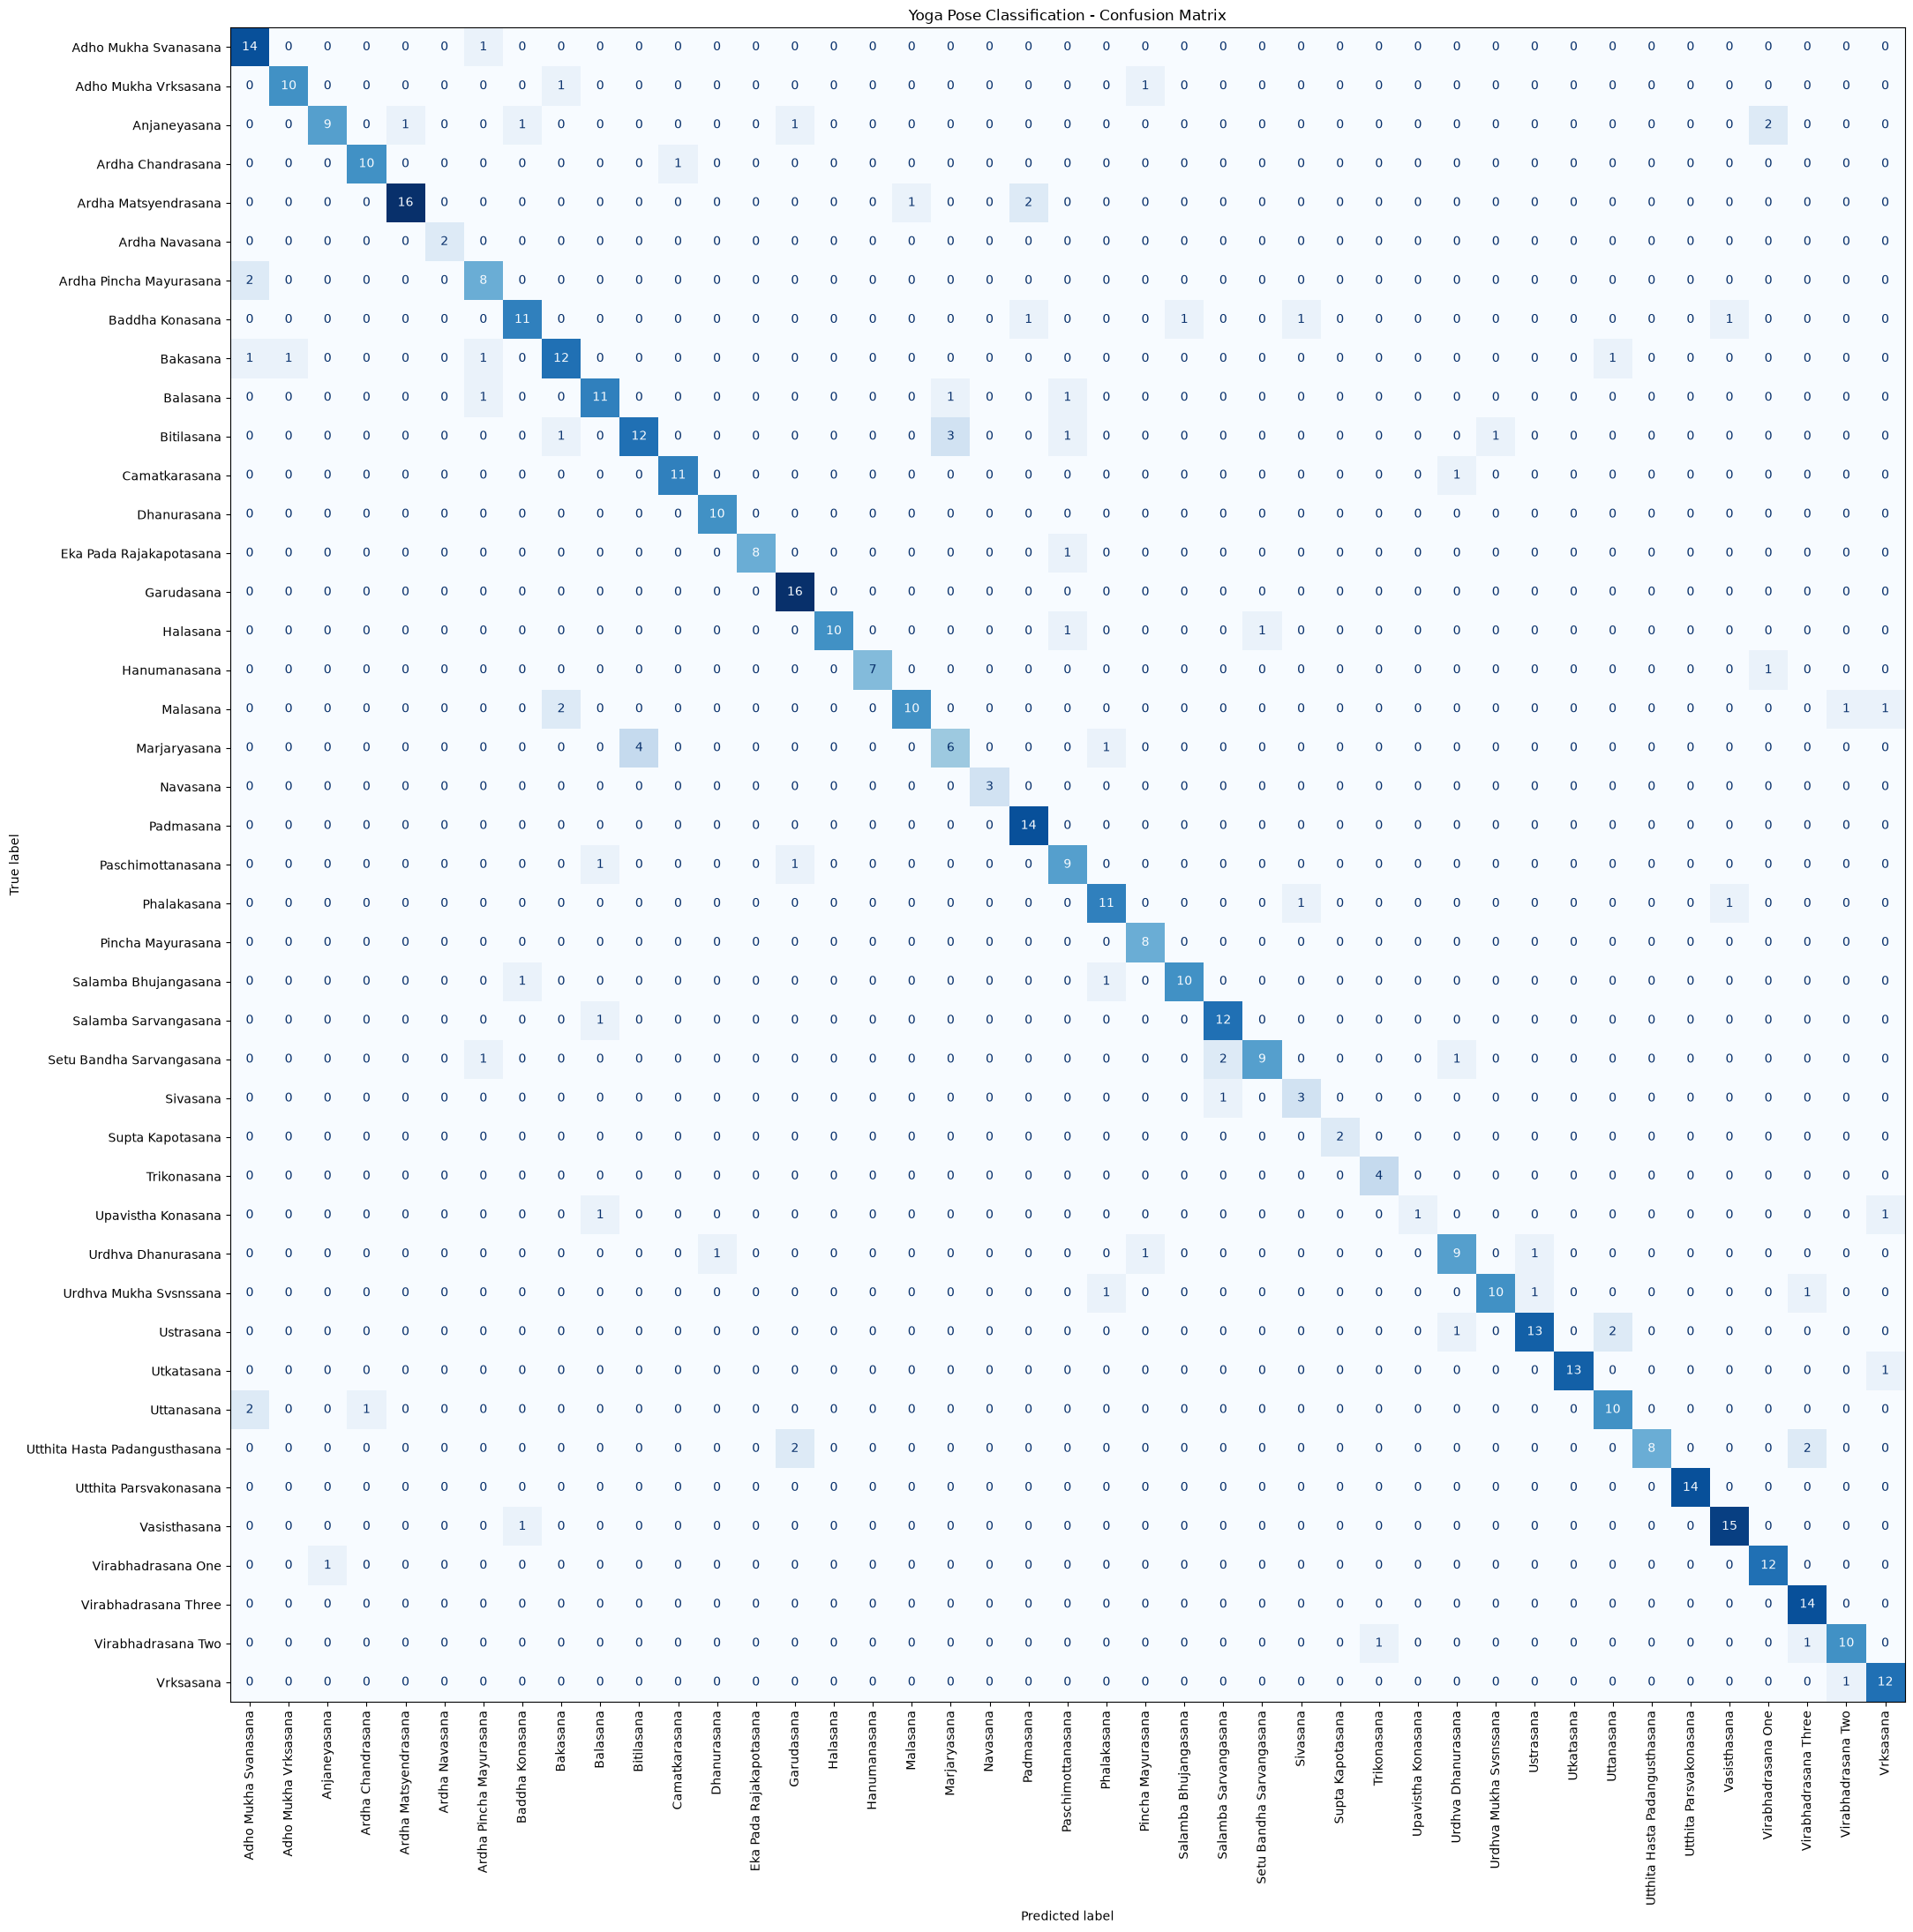

In [10]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, predictions)

fig, ax = plt.subplots(figsize=(22, 22))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=model.classes_
)

disp.plot(
    ax=ax,
    xticks_rotation=90,
    values_format="d",
    cmap="Blues",
    colorbar=False
)

plt.title("Yoga Pose Classification - Confusion Matrix")
plt.tight_layout()
plt.show()

In [11]:
import sys
import platform

print("Python version:")
print(sys.version)

print("\nPython executable:")
print(sys.executable)

print("\nMachine:")
print(platform.machine())

Python version:
3.12.15 (main, Oct  1 2026, 20:49:34) [Clang 22.1.3 ]

Python executable:
/Users/jalshah/Desktop/Sem 5/Projects/YogaFlow/.venv312/bin/python

Machine:
arm64


In [12]:
BaseOptions = mp.tasks.BaseOptions

PoseLandmarker = mp.tasks.vision.PoseLandmarker
PoseLandmarkerOptions = mp.tasks.vision.PoseLandmarkerOptions

VisionRunningMode = mp.tasks.vision.RunningMode

print("MediaPipe Tasks API loaded successfully")

MediaPipe Tasks API loaded successfully


In [13]:
MODEL_PATH = "pose_landmarker.task"

print("Model exists:", os.path.exists(MODEL_PATH))

if os.path.exists(MODEL_PATH):
    print("Model path:", os.path.abspath(MODEL_PATH))
    print("Model size:", os.path.getsize(MODEL_PATH), "bytes")

Model exists: True
Model path: /Users/jalshah/Desktop/Sem 5/Projects/YogaFlow/yoga_analyzer/pose_landmarker.task
Model size: 5777746 bytes


In [14]:
options = PoseLandmarkerOptions(
    base_options=BaseOptions(
        model_asset_path=os.path.abspath(MODEL_PATH)
    ),
    running_mode=VisionRunningMode.IMAGE,
    num_poses=1,
    min_pose_detection_confidence=0.5,
    min_pose_presence_confidence=0.5,
    min_tracking_confidence=0.5
)

landmarker = PoseLandmarker.create_from_options(options)

print("Pose Landmarker loaded successfully!")

Pose Landmarker loaded successfully!


I0000 00:00:1791041520.404957  171178 gl_context.cc:369] GL version: 2.1 (2.1 Metal - 91.7), renderer: Apple M2
W0000 00:00:1791041520.495157  171855 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1791041520.508342  171858 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


In [15]:
from pathlib import Path
DATASET_PATH = Path("YogaDataset")

print("Dataset exists:", DATASET_PATH.exists())
print("Dataset path:", DATASET_PATH.absolute())

Dataset exists: True
Dataset path: /Users/jalshah/Desktop/Sem 5/Projects/YogaFlow/yoga_analyzer/YogaDataset


In [16]:
image_files = []

for ext in ["*.jpg", "*.jpeg", "*.png", "*.JPG", "*.JPEG", "*.PNG"]:
    image_files.extend(DATASET_PATH.rglob(ext))

print("Total images:", len(image_files))

print("\nFirst 5 images:")
for image in image_files[:5]:
    print(image)

Total images: 2756

First 5 images:
YogaDataset/Phalakasana/File52.jpg
YogaDataset/Phalakasana/File53.jpg
YogaDataset/Phalakasana/File51.jpg
YogaDataset/Phalakasana/File50.jpg
YogaDataset/Phalakasana/File54.jpg


In [17]:
pose_folders = sorted([
    folder.name
    for folder in DATASET_PATH.iterdir()
    if folder.is_dir()
])

print("Number of pose classes:", len(pose_folders))

print("\nPose classes:")
for pose in pose_folders:
    print(pose)

Number of pose classes: 47

Pose classes:
Adho Mukha Svanasana
Adho Mukha Vrksasana
Alanasana
Anjaneyasana
Ardha Chandrasana
Ardha Matsyendrasana
Ardha Navasana
Ardha Pincha Mayurasana
Ashta Chandrasana
Baddha Konasana
Bakasana
Balasana
Bitilasana
Camatkarasana
Dhanurasana
Eka Pada Rajakapotasana
Garudasana
Halasana
Hanumanasana
Malasana
Marjaryasana
Navasana
Padmasana
Parsva Virabhadrasana
Parsvottanasana
Paschimottanasana
Phalakasana
Pincha Mayurasana
Salamba Bhujangasana
Salamba Sarvangasana
Setu Bandha Sarvangasana
Sivasana
Supta Kapotasana
Trikonasana
Upavistha Konasana
Urdhva Dhanurasana
Urdhva Mukha Svsnssana
Ustrasana
Utkatasana
Uttanasana
Utthita Hasta Padangusthasana
Utthita Parsvakonasana
Vasisthasana
Virabhadrasana One
Virabhadrasana Three
Virabhadrasana Two
Vrksasana


In [18]:
test_image_path = image_files[0]

print("Testing image:")
print(test_image_path)

image = cv2.imread(str(test_image_path))

print("Image loaded:", image is not None)

if image is not None:
    print("Image shape:", image.shape)

Testing image:
YogaDataset/Phalakasana/File52.jpg
Image loaded: True
Image shape: (575, 575, 3)


In [19]:
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

mp_image = mp.Image(
    image_format=mp.ImageFormat.SRGB,
    data=image_rgb
)

print("Image converted successfully")

Image converted successfully


In [20]:
result = landmarker.detect(mp_image)

print("Number of detected poses:", len(result.pose_landmarks))

Number of detected poses: 1


In [21]:
landmarks = result.pose_landmarks[0]

print("Number of landmarks:", len(landmarks))

Number of landmarks: 33


In [22]:
for i, landmark in enumerate(landmarks):

    print(
        f"{i:2d} | "
        f"x={landmark.x:.4f} | "
        f"y={landmark.y:.4f} | "
        f"z={landmark.z:.4f}"
    )

 0 | x=0.1266 | y=0.5841 | z=0.0206
 1 | x=0.1188 | y=0.5952 | z=0.0378
 2 | x=0.1198 | y=0.5963 | z=0.0378
 3 | x=0.1208 | y=0.5974 | z=0.0378
 4 | x=0.1190 | y=0.5953 | z=-0.0060
 5 | x=0.1199 | y=0.5972 | z=-0.0063
 6 | x=0.1209 | y=0.5987 | z=-0.0063
 7 | x=0.1378 | y=0.6095 | z=0.1285
 8 | x=0.1348 | y=0.6116 | z=-0.0686
 9 | x=0.1441 | y=0.5834 | z=0.0586
10 | x=0.1437 | y=0.5833 | z=0.0012
11 | x=0.2223 | y=0.6288 | z=0.2322
12 | x=0.2028 | y=0.6315 | z=-0.1861
13 | x=0.2293 | y=0.7411 | z=0.2792
14 | x=0.2038 | y=0.7551 | z=-0.3818
15 | x=0.2353 | y=0.8417 | z=0.2931
16 | x=0.2040 | y=0.8625 | z=-0.5793
17 | x=0.2420 | y=0.8601 | z=0.2975
18 | x=0.2102 | y=0.8805 | z=-0.6419
19 | x=0.2434 | y=0.8580 | z=0.2611
20 | x=0.2159 | y=0.8777 | z=-0.6232
21 | x=0.2423 | y=0.8502 | z=0.2744
22 | x=0.2150 | y=0.8712 | z=-0.5766
23 | x=0.4581 | y=0.6665 | z=0.1487
24 | x=0.4511 | y=0.6772 | z=-0.1485
25 | x=0.6393 | y=0.7548 | z=0.1101
26 | x=0.6390 | y=0.7585 | z=-0.1837
27 | x=0.8127 | 

In [23]:
def calculate_angle(a, b, c):

    a = np.array(a)
    b = np.array(b)
    c = np.array(c)

    ba = a - b
    bc = c - b

    denominator = (
        np.linalg.norm(ba) *
        np.linalg.norm(bc)
    )

    if denominator == 0:
        return np.nan

    cosine_angle = np.dot(ba, bc) / denominator

    cosine_angle = np.clip(
        cosine_angle,
        -1.0,
        1.0
    )

    angle = np.degrees(
        np.arccos(cosine_angle)
    )

    return float(angle)

In [24]:
def get_point(landmarks, index):

    landmark = landmarks[index]

    return [
        landmark.x,
        landmark.y,
        landmark.z
    ]

In [25]:
def calculate_pose_angles(landmarks):

    angles = {}

    # -------------------------
    # LEFT ELBOW
    # Shoulder → Elbow → Wrist
    # -------------------------
    angles["left_elbow"] = calculate_angle(
        get_point(landmarks, 11),
        get_point(landmarks, 13),
        get_point(landmarks, 15)
    )

    # -------------------------
    # RIGHT ELBOW
    # -------------------------
    angles["right_elbow"] = calculate_angle(
        get_point(landmarks, 12),
        get_point(landmarks, 14),
        get_point(landmarks, 16)
    )

    # -------------------------
    # LEFT KNEE
    # Hip → Knee → Ankle
    # -------------------------
    angles["left_knee"] = calculate_angle(
        get_point(landmarks, 23),
        get_point(landmarks, 25),
        get_point(landmarks, 27)
    )

    # -------------------------
    # RIGHT KNEE
    # -------------------------
    angles["right_knee"] = calculate_angle(
        get_point(landmarks, 24),
        get_point(landmarks, 26),
        get_point(landmarks, 28)
    )

    # -------------------------
    # LEFT HIP
    # Shoulder → Hip → Knee
    # -------------------------
    angles["left_hip"] = calculate_angle(
        get_point(landmarks, 11),
        get_point(landmarks, 23),
        get_point(landmarks, 25)
    )

    # -------------------------
    # RIGHT HIP
    # -------------------------
    angles["right_hip"] = calculate_angle(
        get_point(landmarks, 12),
        get_point(landmarks, 24),
        get_point(landmarks, 26)
    )

    # -------------------------
    # LEFT SHOULDER
    # Hip → Shoulder → Elbow
    # -------------------------
    angles["left_shoulder"] = calculate_angle(
        get_point(landmarks, 23),
        get_point(landmarks, 11),
        get_point(landmarks, 13)
    )

    # -------------------------
    # RIGHT SHOULDER
    # -------------------------
    angles["right_shoulder"] = calculate_angle(
        get_point(landmarks, 24),
        get_point(landmarks, 12),
        get_point(landmarks, 14)
    )

    return angles

In [26]:
angles = calculate_pose_angles(landmarks)

print("Joint Angles:")
print("-" * 40)

for joint, angle in angles.items():

    if np.isnan(angle):
        print(f"{joint:20s}: NaN")
    else:
        print(f"{joint:20s}: {angle:.2f}°")

Joint Angles:
----------------------------------------
left_elbow          : 165.14°
right_elbow         : 176.25°
left_knee           : 153.13°
right_knee          : 158.44°
left_hip            : 161.64°
right_hip           : 157.66°
left_shoulder       : 86.39°
right_shoulder      : 91.42°


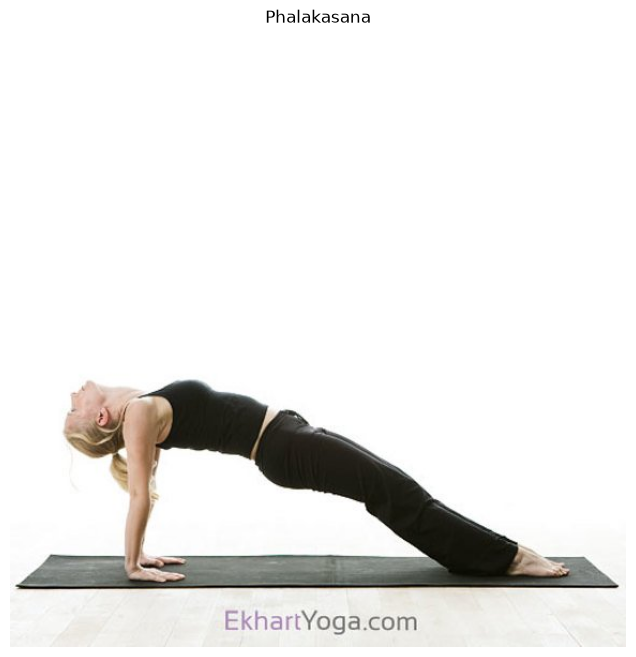

In [27]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 8))

plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))

plt.axis("off")
plt.title(test_image_path.parent.name)

plt.show()

In [28]:
angle_records = []

total = len(image_files)

for count, image_path in enumerate(image_files, start=1):

    try:

        # Pose name = parent folder name
        pose_name = image_path.parent.name

        # Read image
        image = cv2.imread(str(image_path))

        if image is None:
            continue

        # BGR → RGB
        image_rgb = cv2.cvtColor(
            image,
            cv2.COLOR_BGR2RGB
        )

        # MediaPipe image
        mp_image = mp.Image(
            image_format=mp.ImageFormat.SRGB,
            data=image_rgb
        )

        # Detect pose
        result = landmarker.detect(mp_image)

        # Skip images where no pose is detected
        if len(result.pose_landmarks) == 0:
            continue

        # Get landmarks
        landmarks = result.pose_landmarks[0]

        # Calculate angles
        angles = calculate_pose_angles(landmarks)

        # Create record
        record = {
            "pose": pose_name,
            "image": str(image_path)
        }

        record.update(angles)

        angle_records.append(record)

    except Exception as e:

        print(
            f"Error processing {image_path}: {e}"
        )

    # Progress
    if count % 100 == 0:

        print(
            f"Processed {count}/{total}"
        )

print("\nFinished!")
print("Successful pose detections:", len(angle_records))

Processed 100/2756
Processed 200/2756
Processed 300/2756
Processed 400/2756
Processed 500/2756


libpng warning: cHRM: inconsistent chromaticities
libpng warning: iCCP: known incorrect sRGB profile
libpng warning: iCCP: known incorrect sRGB profile


Processed 600/2756
Processed 700/2756
Processed 800/2756
Processed 900/2756
Processed 1000/2756
Processed 1100/2756


libpng warning: iCCP: known incorrect sRGB profile


Processed 1200/2756
Processed 1300/2756
Processed 1400/2756
Processed 1600/2756
Processed 1700/2756
Processed 1800/2756
Processed 1900/2756
Processed 2000/2756
Processed 2100/2756
Processed 2200/2756
Processed 2300/2756
Processed 2400/2756
Processed 2500/2756
Processed 2600/2756
Processed 2700/2756

Finished!
Successful pose detections: 2578


In [29]:
angle_df = pd.DataFrame(angle_records)

print("Dataset shape:", angle_df.shape)

angle_df.head()

Dataset shape: (2578, 10)


,pose,image,left_elbow,right_elbow,left_knee,right_knee,left_hip,right_hip,left_shoulder,right_shoulder
0,Phalakasana,YogaDataset/Phalakasana/File52.jpg,165.143201,176.250268,153.133702,158.436388,161.644408,157.661244,86.388672,91.424545
1,Phalakasana,YogaDataset/Phalakasana/File53.jpg,90.653879,111.940831,160.544960,155.594982,155.175510,151.151983,45.092451,41.691472
2,Phalakasana,YogaDataset/Phalakasana/File51.jpg,175.464564,153.881328,158.713901,155.524881,157.334125,161.354354,80.176019,69.232889
3,Phalakasana,YogaDataset/Phalakasana/File50.jpg,127.763997,110.699610,166.343311,168.840289,137.873199,158.076951,96.971235,88.513910
4,Phalakasana,YogaDataset/Phalakasana/File54.jpg,172.937651,123.402398,171.111911,173.271067,159.238553,153.394482,103.438681,68.093667


In [30]:
print(angle_df.isnull().sum())

pose              0
image             0
left_elbow        0
right_elbow       0
left_knee         0
right_knee        0
left_hip          0
right_hip         0
left_shoulder     0
right_shoulder    0
dtype: int64


In [31]:
pose_counts = angle_df["pose"].value_counts()

print(pose_counts)

pose
Ardha Matsyendrasana             93
Bitilasana                       90
Ustrasana                        82
Garudasana                       82
Vasisthasana                     80
Bakasana                         79
Baddha Konasana                  76
Adho Mukha Svanasana             73
Anjaneyasana                     71
Balasana                         70
Utkatasana                       69
Padmasana                        68
Malasana                         68
Virabhadrasana Three             68
Utthita Parsvakonasana           68
Vrksasana                        67
Phalakasana                      66
Uttanasana                       66
Setu Bandha Sarvangasana         65
Salamba Sarvangasana             65
Urdhva Mukha Svsnssana           65
Virabhadrasana One               63
Utthita Hasta Padangusthasana    62
Camatkarasana                    61
Halasana                         60
Virabhadrasana Two               60
Salamba Bhujangasana             59
Adho Mukha Vrksasana   

In [32]:
print("Number of poses:", angle_df["pose"].nunique())

Number of poses: 47


In [33]:
ANGLE_DATASET_PATH = "yoga_pose_angles.csv"

angle_df.to_csv(
    ANGLE_DATASET_PATH,
    index=False
)

print(
    "Saved:",
    ANGLE_DATASET_PATH
)

Saved: yoga_pose_angles.csv


In [34]:
reference_profile = {}

angle_columns = [
    "left_elbow",
    "right_elbow",
    "left_knee",
    "right_knee",
    "left_hip",
    "right_hip",
    "left_shoulder",
    "right_shoulder"
]

for pose_name, group in angle_df.groupby("pose"):

    reference_profile[pose_name] = {}

    for angle_name in angle_columns:

        values = group[angle_name].dropna()

        if len(values) == 0:
            continue

        reference_profile[pose_name][angle_name] = {

            "lower": float(
                values.quantile(0.10)
            ),

            "median": float(
                values.median()
            ),

            "upper": float(
                values.quantile(0.90)
            ),

            "samples": int(
                len(values)
            )
        }

print(
    "Reference profiles created:",
    len(reference_profile)
)

Reference profiles created: 47


In [35]:
first_pose = list(reference_profile.keys())[0]

print("Pose:", first_pose)

for joint, values in reference_profile[first_pose].items():

    print(
        f"{joint:20s} "
        f"{values['lower']:.1f}° - "
        f"{values['upper']:.1f}° "
        f"(median={values['median']:.1f}°)"
    )

Pose: Adho Mukha Svanasana
left_elbow           86.5° - 143.1° (median=112.9°)
right_elbow          83.0° - 136.3° (median=103.9°)
left_knee            155.1° - 175.8° (median=169.6°)
right_knee           151.6° - 175.6° (median=168.2°)
left_hip             46.1° - 80.1° (median=60.0°)
right_hip            46.6° - 93.5° (median=60.8°)
left_shoulder        134.2° - 158.1° (median=144.5°)
right_shoulder       133.7° - 164.3° (median=146.5°)


In [36]:
import json
REFERENCE_PATH = "yoga_reference_profiles.json"

with open(
    REFERENCE_PATH,
    "w"
) as f:

    json.dump(
        reference_profile,
        f,
        indent=4
    )

print(
    "Saved:",
    REFERENCE_PATH
)

Saved: yoga_reference_profiles.json


In [37]:
with open(
    "yoga_reference_profiles.json",
    "r"
) as f:

    reference_profile = json.load(f)

print(
    "Reference profiles loaded:",
    len(reference_profile)
)

Reference profiles loaded: 47


In [38]:
def evaluate_posture(
    pose_name,
    angles,
    reference_profile
):

    if pose_name not in reference_profile:

        return {
            "score": 0,
            "status": "Unknown",
            "issues": []
        }

    profile = reference_profile[pose_name]

    scores = []
    issues = []

    for joint, current_angle in angles.items():

        if joint not in profile:
            continue

        if np.isnan(current_angle):
            continue

        lower = profile[joint]["lower"]
        upper = profile[joint]["upper"]

        # Correct range
        if lower <= current_angle <= upper:

            scores.append(1.0)

        # Outside correct range
        else:

            if current_angle < lower:

                difference = lower - current_angle
                direction = "too_low"

            else:

                difference = current_angle - upper
                direction = "too_high"

            # Convert difference into score
            joint_score = max(
                0.0,
                1.0 - difference / 45.0
            )

            scores.append(joint_score)

            issues.append({

                "joint": joint,

                "current": round(
                    float(current_angle),
                    1
                ),

                "expected_lower": round(
                    float(lower),
                    1
                ),

                "expected_upper": round(
                    float(upper),
                    1
                ),

                "direction": direction

            })

    # Overall score
    if scores:

        score = np.mean(scores) * 100

    else:

        score = 0

    return {

        "score": round(
            float(score),
            1
        ),

        "issues": issues

    }

In [39]:
def get_posture_status(score):

    if score >= 90:
        return "Excellent"

    elif score >= 75:
        return "Good"

    elif score >= 60:
        return "Needs Improvement"

    else:
        return "Incorrect"

In [40]:
pose_name = test_image_path.parent.name

evaluation = evaluate_posture(
    pose_name,
    angles,
    reference_profile
)

score = evaluation["score"]

print("Pose:", pose_name)
print("Posture Score:", score)
print("Status:", get_posture_status(score))

print("\nIssues:")

if len(evaluation["issues"]) == 0:

    print("No major posture issues detected.")

else:

    for issue in evaluation["issues"]:

        print(issue)

Pose: Phalakasana
Posture Score: 38.3
Status: Incorrect

Issues:
{'joint': 'left_knee', 'current': 131.3, 'expected_lower': 143.2, 'expected_upper': 171.1, 'direction': 'too_low'}
{'joint': 'right_knee', 'current': 81.0, 'expected_lower': 146.2, 'expected_upper': 173.9, 'direction': 'too_low'}
{'joint': 'left_hip', 'current': 103.3, 'expected_lower': 133.4, 'expected_upper': 161.0, 'direction': 'too_low'}
{'joint': 'right_hip', 'current': 84.5, 'expected_lower': 139.3, 'expected_upper': 164.2, 'direction': 'too_low'}
{'joint': 'left_shoulder', 'current': 160.3, 'expected_lower': 54.9, 'expected_upper': 96.1, 'direction': 'too_high'}
{'joint': 'right_shoulder', 'current': 155.5, 'expected_lower': 58.4, 'expected_upper': 99.4, 'direction': 'too_high'}


In [41]:
def generate_correction(issue):

    joint = issue["joint"]
    direction = issue["direction"]

    corrections = {

        ("left_knee", "too_low"):
            "Straighten your left knee slightly.",

        ("right_knee", "too_low"):
            "Straighten your right knee slightly.",

        ("left_knee", "too_high"):
            "Bend your left knee slightly.",

        ("right_knee", "too_high"):
            "Bend your right knee slightly.",

        ("left_elbow", "too_low"):
            "Adjust your left elbow position.",

        ("right_elbow", "too_low"):
            "Adjust your right elbow position.",

        ("left_elbow", "too_high"):
            "Adjust your left elbow position.",

        ("right_elbow", "too_high"):
            "Adjust your right elbow position.",

        ("left_hip", "too_low"):
            "Adjust your left hip alignment.",

        ("right_hip", "too_low"):
            "Adjust your right hip alignment.",

        ("left_hip", "too_high"):
            "Adjust your left hip alignment.",

        ("right_hip", "too_high"):
            "Adjust your right hip alignment.",

        ("left_shoulder", "too_low"):
            "Adjust your left shoulder position.",

        ("right_shoulder", "too_low"):
            "Adjust your right shoulder position.",

        ("left_shoulder", "too_high"):
            "Adjust your left shoulder position.",

        ("right_shoulder", "too_high"):
            "Adjust your right shoulder position."
    }

    return corrections.get(
        (joint, direction),
        f"Adjust your {joint.replace('_', ' ')}."
    )

In [42]:
print("=" * 50)

print("AI YOGA COACH")

print("=" * 50)

print("Pose:", pose_name)

print(
    "Posture Score:",
    evaluation["score"],
    "/ 100"
)

print(
    "Status:",
    get_posture_status(
        evaluation["score"]
    )
)

print("\nCOACHING FEEDBACK")
print("-" * 50)

if len(evaluation["issues"]) == 0:

    print(
        "Excellent! Your posture is "
        "within the learned reference range."
    )

else:

    for issue in evaluation["issues"]:

        correction = generate_correction(issue)

        print(
            f"\nBody Part: "
            f"{issue['joint'].replace('_', ' ').title()}"
        )

        print(
            f"Current Angle: "
            f"{issue['current']}°"
        )

        print(
            f"Expected Range: "
            f"{issue['expected_lower']}° - "
            f"{issue['expected_upper']}°"
        )

        print(
            f"Correction: {correction}"
        )

AI YOGA COACH
Pose: Phalakasana
Posture Score: 38.3 / 100
Status: Incorrect

COACHING FEEDBACK
--------------------------------------------------

Body Part: Left Knee
Current Angle: 131.3°
Expected Range: 143.2° - 171.1°
Correction: Straighten your left knee slightly.

Body Part: Right Knee
Current Angle: 81.0°
Expected Range: 146.2° - 173.9°
Correction: Straighten your right knee slightly.

Body Part: Left Hip
Current Angle: 103.3°
Expected Range: 133.4° - 161.0°
Correction: Adjust your left hip alignment.

Body Part: Right Hip
Current Angle: 84.5°
Expected Range: 139.3° - 164.2°
Correction: Adjust your right hip alignment.

Body Part: Left Shoulder
Current Angle: 160.3°
Expected Range: 54.9° - 96.1°
Correction: Adjust your left shoulder position.

Body Part: Right Shoulder
Current Angle: 155.5°
Expected Range: 58.4° - 99.4°
Correction: Adjust your right shoulder position.


In [43]:
def display_coaching_result(
    pose_name,
    evaluation
):

    score = evaluation["score"]

    print("\n" + "=" * 60)
    print("                 AI YOGA COACH")
    print("=" * 60)

    print(f"Pose           : {pose_name}")
    print(f"Posture Score  : {score}/100")
    print(
        f"Status         : "
        f"{get_posture_status(score)}"
    )

    print("\nFeedback")
    print("-" * 60)

    if not evaluation["issues"]:

        print(
            "Your posture looks good. "
            "Keep holding the position."
        )

    else:

        # Show maximum 3 most important issues
        for issue in evaluation["issues"][:3]:

            correction = generate_correction(issue)

            print(
                f"• {issue['joint'].replace('_', ' ').title()}"
            )

            print(
                f"  Current : {issue['current']}°"
            )

            print(
                f"  Target  : "
                f"{issue['expected_lower']}° - "
                f"{issue['expected_upper']}°"
            )

            print(
                f"  Fix     : {correction}"
            )

    print("=" * 60)

In [44]:
test_index = 10

test_image_path = image_files[test_index]

image = cv2.imread(
    str(test_image_path)
)

image_rgb = cv2.cvtColor(
    image,
    cv2.COLOR_BGR2RGB
)

mp_image = mp.Image(
    image_format=mp.ImageFormat.SRGB,
    data=image_rgb
)

result = landmarker.detect(mp_image)

if len(result.pose_landmarks) > 0:

    landmarks = result.pose_landmarks[0]

    angles = calculate_pose_angles(
        landmarks
    )

    pose_name = test_image_path.parent.name

    evaluation = evaluate_posture(
        pose_name,
        angles,
        reference_profile
    )

    display_coaching_result(
        pose_name,
        evaluation
    )

else:

    print("No pose detected.")


                 AI YOGA COACH
Pose           : Padmasana
Posture Score  : 93.9/100
Status         : Excellent

Feedback
------------------------------------------------------------
• Right Elbow
  Current : 157.3°
  Target  : 107.0° - 136.5°
  Fix     : Adjust your right elbow position.
• Left Shoulder
  Current : 16.4°
  Target  : 17.4° - 72.8°
  Fix     : Adjust your left shoulder position.


In [45]:
phase2_report = {
    "total_images": len(image_files),
    "successful_pose_detections": len(angle_records),
    "number_of_pose_classes": int(
        angle_df["pose"].nunique()
    ),
    "angle_features": angle_columns,
    "reference_profiles": len(reference_profile)
}

with open(
    "phase2_report.json",
    "w"
) as f:

    json.dump(
        phase2_report,
        f,
        indent=4
    )

print(
    json.dumps(
        phase2_report,
        indent=4
    )
)

{
    "total_images": 2756,
    "successful_pose_detections": 2578,
    "number_of_pose_classes": 47,
    "angle_features": [
        "left_elbow",
        "right_elbow",
        "left_knee",
        "right_knee",
        "left_hip",
        "right_hip",
        "left_shoulder",
        "right_shoulder"
    ],
    "reference_profiles": 47
}


In [46]:
print("Checking Phase 2...")

print("Landmarker:", "landmarker" in globals())
print("Reference profile:", "reference_profile" in globals())
print("Angle function:", "calculate_pose_angles" in globals())
print("Posture evaluator:", "evaluate_posture" in globals())

Checking Phase 2...
Landmarker: True
Reference profile: True
Angle function: True
Posture evaluator: True


In [47]:
import joblib

# Save trained classifier
joblib.dump(
    model,
    "yoga_pose_classifier.pkl"
)

# Save label encoder
joblib.dump(
    label_encoder,
    "yoga_label_encoder.pkl"
)

print("Classifier saved successfully!")
print("Label encoder saved successfully!")

Classifier saved successfully!
Label encoder saved successfully!


In [48]:
def extract_landmark_features(landmarks):

    features = []

    for landmark in landmarks:

        features.extend([
            landmark.x,
            landmark.y,
            landmark.z
        ])

    return np.array(features)

In [49]:
features = extract_landmark_features(landmarks)

print("Number of features:", len(features))

Number of features: 99


In [50]:
import joblib

classifier = joblib.load(
    "yoga_pose_classifier.pkl"
)

label_encoder = joblib.load(
    "yoga_label_encoder.pkl"
)

print("Classifier loaded successfully")
print("Label encoder loaded successfully")

Classifier loaded successfully
Label encoder loaded successfully


In [51]:
print("Classifier expects:", classifier.n_features_in_)
print("Current features:", len(features))

Classifier expects: 132
Current features: 99


In [52]:
def extract_landmark_features(landmarks):
    features = []

    for landmark in landmarks:
        features.extend([
            landmark.x,
            landmark.y,
            landmark.z,
            landmark.visibility
        ])

    return np.array(features, dtype=np.float32)

In [53]:
features = extract_landmark_features(result.pose_landmarks[0])

print("Number of features:", len(features))

Number of features: 132


In [54]:
features_input = features.reshape(1, -1)

prediction = classifier.predict(features_input)

print("Prediction:", prediction)

Prediction: ['Padmasana']


/Users/jalshah/Desktop/Sem 5/Projects/YogaFlow/.venv312/lib/python3.12/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


In [55]:
print(classifier.feature_names_in_)
print(len(classifier.feature_names_in_))

['x_0' 'y_0' 'z_0' 'visibility_0' 'x_1' 'y_1' 'z_1' 'visibility_1' 'x_2'
 'y_2' 'z_2' 'visibility_2' 'x_3' 'y_3' 'z_3' 'visibility_3' 'x_4' 'y_4'
 'z_4' 'visibility_4' 'x_5' 'y_5' 'z_5' 'visibility_5' 'x_6' 'y_6' 'z_6'
 'visibility_6' 'x_7' 'y_7' 'z_7' 'visibility_7' 'x_8' 'y_8' 'z_8'
 'visibility_8' 'x_9' 'y_9' 'z_9' 'visibility_9' 'x_10' 'y_10' 'z_10'
 'visibility_10' 'x_11' 'y_11' 'z_11' 'visibility_11' 'x_12' 'y_12' 'z_12'
 'visibility_12' 'x_13' 'y_13' 'z_13' 'visibility_13' 'x_14' 'y_14' 'z_14'
 'visibility_14' 'x_15' 'y_15' 'z_15' 'visibility_15' 'x_16' 'y_16' 'z_16'
 'visibility_16' 'x_17' 'y_17' 'z_17' 'visibility_17' 'x_18' 'y_18' 'z_18'
 'visibility_18' 'x_19' 'y_19' 'z_19' 'visibility_19' 'x_20' 'y_20' 'z_20'
 'visibility_20' 'x_21' 'y_21' 'z_21' 'visibility_21' 'x_22' 'y_22' 'z_22'
 'visibility_22' 'x_23' 'y_23' 'z_23' 'visibility_23' 'x_24' 'y_24' 'z_24'
 'visibility_24' 'x_25' 'y_25' 'z_25' 'visibility_25' 'x_26' 'y_26' 'z_26'
 'visibility_26' 'x_27' 'y_27' 'z_27' 'visib

In [56]:
features_input = pd.DataFrame(
    [features],
    columns=classifier.feature_names_in_
)

prediction = classifier.predict(features_input)

print("Prediction:", prediction)

Prediction: ['Padmasana']


In [57]:
print("Prediction:", prediction)
print("Prediction type:", type(prediction))
print("Prediction value type:", type(prediction[0]))

print("Classifier classes:")
print(classifier.classes_)

Prediction: ['Padmasana']
Prediction type: <class 'numpy.ndarray'>
Prediction value type: <class 'str'>
Classifier classes:
['Adho Mukha Svanasana' 'Adho Mukha Vrksasana' 'Anjaneyasana'
 'Ardha Chandrasana' 'Ardha Matsyendrasana' 'Ardha Navasana'
 'Ardha Pincha Mayurasana' 'Baddha Konasana' 'Bakasana' 'Balasana'
 'Bitilasana' 'Camatkarasana' 'Dhanurasana' 'Eka Pada Rajakapotasana'
 'Garudasana' 'Halasana' 'Hanumanasana' 'Malasana' 'Marjaryasana'
 'Navasana' 'Padmasana' 'Paschimottanasana' 'Phalakasana'
 'Pincha Mayurasana' 'Salamba Bhujangasana' 'Salamba Sarvangasana'
 'Setu Bandha Sarvangasana' 'Sivasana' 'Supta Kapotasana' 'Trikonasana'
 'Upavistha Konasana' 'Urdhva Dhanurasana' 'Urdhva Mukha Svsnssana'
 'Ustrasana' 'Utkatasana' 'Uttanasana' 'Utthita Hasta Padangusthasana'
 'Utthita Parsvakonasana' 'Vasisthasana' 'Virabhadrasana One'
 'Virabhadrasana Three' 'Virabhadrasana Two' 'Vrksasana']


In [58]:
features = extract_landmark_features(landmarks)

features_input = features.reshape(1, -1)

prediction = classifier.predict(features_input)

predicted_pose = prediction[0]

print("Predicted pose:", predicted_pose)

Predicted pose: Padmasana


/Users/jalshah/Desktop/Sem 5/Projects/YogaFlow/.venv312/lib/python3.12/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


In [59]:
from mediapipe.tasks.python import vision
from mediapipe import Image, ImageFormat

test_image_path = "YogaDataset/Trikonasana/example.jpg"

In [60]:
from pathlib import Path

dataset_path = Path("YogaDataset")

image_files = list(dataset_path.rglob("*.jpg")) + \
              list(dataset_path.rglob("*.jpeg")) + \
              list(dataset_path.rglob("*.png"))

print("Total images:", len(image_files))

for path in image_files[:10]:
    print(path)

Total images: 2756
YogaDataset/Phalakasana/File52.jpg
YogaDataset/Phalakasana/File53.jpg
YogaDataset/Phalakasana/File51.jpg
YogaDataset/Phalakasana/File50.jpg
YogaDataset/Phalakasana/File54.jpg
YogaDataset/Phalakasana/File55.jpg
YogaDataset/Phalakasana/File57.jpg
YogaDataset/Phalakasana/File56.jpg
YogaDataset/Ardha Navasana/File13.jpg
YogaDataset/Adho Mukha Svanasana/File25.jpg


In [61]:
test_image_path = str(image_files[0])

print("Testing image:")
print(test_image_path)

Testing image:
YogaDataset/Phalakasana/File52.jpg


In [62]:
image = cv2.imread(test_image_path)

if image is None:
    print("ERROR: Could not read the image.")
else:
    print("Image loaded successfully.")
    print("Image shape:", image.shape)

Image loaded successfully.
Image shape: (575, 575, 3)


In [63]:
rgb_image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

mp_image = mp.Image(
    image_format=mp.ImageFormat.SRGB,
    data=rgb_image
)

result = landmarker.detect(mp_image)

print("Number of poses detected:", len(result.pose_landmarks))

Number of poses detected: 1


In [64]:
from mediapipe.tasks.python.vision import drawing_utils
from mediapipe.tasks.python.vision import drawing_styles
from mediapipe.tasks.python.vision import pose_landmarker

annotated_image = np.copy(rgb_image)

pose_landmarks = result.pose_landmarks[0]

drawing_utils.draw_landmarks(
    annotated_image,
    pose_landmarks,
    pose_landmarker.PoseLandmarksConnections.POSE_LANDMARKS,
    drawing_styles.get_default_pose_landmarks_style()
)

display(annotated_image)

ImportError: cannot import name 'drawing_utils' from 'mediapipe.tasks.python.vision' (/Users/jalshah/Desktop/Sem 5/Projects/YogaFlow/.venv312/lib/python3.12/site-packages/mediapipe/tasks/python/vision/__init__.py)

In [ ]:
landmarks = result.pose_landmarks[0]

print("Landmarks detected:", len(landmarks))

Landmarks detected: 33


In [ ]:
features = extract_landmark_features(landmarks)

print("Feature count:", len(features))

Feature count: 132


In [ ]:
features_input = features.reshape(1, -1)

prediction = classifier.predict(features_input)

predicted_pose = prediction[0]

print("Predicted pose:", predicted_pose)

Predicted pose: Phalakasana


/Users/jalshah/Desktop/SIH/venv/lib/python3.12/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


In [ ]:
angles = calculate_pose_angles(landmarks)

for joint, angle in angles.items():
    print(f"{joint}: {angle:.1f}°")

left_elbow: 165.1°
right_elbow: 176.3°
left_knee: 153.1°
right_knee: 158.4°
left_hip: 161.6°
right_hip: 157.7°
left_shoulder: 86.4°
right_shoulder: 91.4°


In [ ]:
posture_result = evaluate_posture(
    predicted_pose,
    angles,
    reference_profile
)

print("Pose:", predicted_pose)
print("Posture Score:", posture_result["score"])
print("Issues:", posture_result["issues"])

Pose: Phalakasana
Posture Score: 97.3
Issues: [{'joint': 'right_elbow', 'current': 176.3, 'expected_lower': 91.2, 'expected_upper': 167.2, 'direction': 'too_high'}, {'joint': 'left_hip', 'current': 161.6, 'expected_lower': 133.4, 'expected_upper': 161.0, 'direction': 'too_high'}]


In [ ]:
correction_map = {
    ("left_knee", "too_low"):
        "Straighten your left knee slightly.",

    ("right_knee", "too_low"):
        "Straighten your right knee slightly.",

    ("left_knee", "too_high"):
        "Bend your left knee slightly.",

    ("right_knee", "too_high"):
        "Bend your right knee slightly.",

    ("left_elbow", "too_low"):
        "Straighten your left elbow slightly.",

    ("right_elbow", "too_low"):
        "Straighten your right elbow slightly.",

    ("left_elbow", "too_high"):
        "Bend your left elbow slightly.",

    ("right_elbow", "too_high"):
        "Bend your right elbow slightly.",

    ("left_hip", "too_low"):
        "Adjust your left hip position slightly.",

    ("right_hip", "too_low"):
        "Adjust your right hip position slightly.",

    ("left_hip", "too_high"):
        "Adjust your left hip position slightly.",

    ("right_hip", "too_high"):
        "Adjust your right hip position slightly.",

    ("left_shoulder", "too_low"):
        "Adjust your left shoulder position slightly.",

    ("right_shoulder", "too_low"):
        "Adjust your right shoulder position slightly.",

    ("left_shoulder", "too_high"):
        "Lower your left shoulder slightly.",

    ("right_shoulder", "too_high"):
        "Lower your right shoulder slightly."
}

In [ ]:
if len(posture_result["issues"]) == 0:
    print("Posture is correct. Keep holding the pose.")
else:
    for issue in posture_result["issues"]:
        key = (issue["joint"], issue["direction"])

        correction = correction_map.get(
            key,
            f"Adjust your {issue['joint'].replace('_', ' ')}."
        )

        print("Wrong body part:", issue["joint"].replace("_", " "))
        print("Correction:", correction)

Wrong body part: right elbow
Correction: Bend your right elbow slightly.
Wrong body part: left hip
Correction: Adjust your left hip position slightly.


In [ ]:
import cv2

cap = cv2.VideoCapture(0)

if not cap.isOpened():
    print("Could not open webcam")
else:
    print("Webcam opened successfully")

cap.release()

Webcam opened successfully


In [ ]:
cap = cv2.VideoCapture(0)

ret, frame = cap.read()

cap.release()

print("Frame captured:", ret)

if ret:
    print("Frame shape:", frame.shape)

Frame captured: True
Frame shape: (1080, 1920, 3)


In [ ]:
rgb_frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

mp_image = mp.Image(
    image_format=mp.ImageFormat.SRGB,
    data=rgb_frame
)

result = landmarker.detect(mp_image)

print("Poses detected:", len(result.pose_landmarks))

Poses detected: 1


In [ ]:
if len(result.pose_landmarks) > 0:

    landmarks = result.pose_landmarks[0]

    features = extract_landmark_features(landmarks)

    print("Features:", len(features))

    features_input = features.reshape(1, -1)

    prediction = classifier.predict(features_input)

    predicted_pose = prediction[0]

    print("Predicted pose:", predicted_pose)

else:
    print("No person detected")

Features: 132
Predicted pose: Baddha Konasana


/Users/jalshah/Desktop/SIH/venv/lib/python3.12/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


In [ ]:
if len(result.pose_landmarks) > 0:

    landmarks = result.pose_landmarks[0]

    features = extract_landmark_features(landmarks)
    features_input = features.reshape(1, -1)

    prediction = classifier.predict(features_input)
    predicted_pose = prediction[0]

    angles = calculate_pose_angles(landmarks)

    posture_result = evaluate_posture(
        predicted_pose,
        angles,
        reference_profile
    )

    score = posture_result["score"]
    status = get_posture_status(score)

    print("Pose:", predicted_pose)
    print("Score:", score)
    print("Status:", status)

else:
    print("No person detected")

Pose: Baddha Konasana
Score: 76.1
Status: Good


/Users/jalshah/Desktop/SIH/venv/lib/python3.12/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


In [ ]:
if len(posture_result["issues"]) == 0:

    correction = "Excellent! Keep holding the pose."

else:

    issue = posture_result["issues"][0]

    key = (
        issue["joint"],
        issue["direction"]
    )

    correction = correction_map.get(
        key,
        f"Adjust your {issue['joint'].replace('_', ' ')}."
    )

print("Correction:", correction)

Correction: Straighten your right elbow slightly.


In [ ]:
annotated_frame = np.copy(rgb_frame)

if len(result.pose_landmarks) > 0:

    pose_landmarks = result.pose_landmarks[0]

    drawing_utils.draw_landmarks(
        annotated_frame,
        pose_landmarks,
        pose_landmarker.PoseLandmarksConnections.POSE_LANDMARKS,
        drawing_styles.get_default_pose_landmarks_style()
    )

display(annotated_frame)

array([[[ 25,  23,  19],
        [ 25,  23,  19],
        [ 24,  22,  18],
        ...,
        [134, 130, 126],
        [148, 144, 140],
        [144, 140, 136]],

       [[ 25,  23,  19],
        [ 26,  25,  18],
        [ 25,  23,  17],
        ...,
        [138, 136, 130],
        [143, 139, 133],
        [141, 137, 131]],

       [[ 25,  23,  19],
        [ 23,  21,  14],
        [ 25,  23,  17],
        ...,
        [142, 141, 132],
        [157, 154, 145],
        [169, 165, 157]],

       ...,

       [[ 34,  28,  25],
        [ 32,  26,  22],
        [ 30,  23,  20],
        ...,
        [ 25,  28,  22],
        [ 28,  31,  26],
        [ 28,  31,  26]],

       [[ 27,  21,  18],
        [ 27,  21,  18],
        [ 28,  22,  19],
        ...,
        [ 26,  29,  26],
        [ 24,  26,  23],
        [ 22,  25,  22]],

       [[ 23,  16,  13],
        [ 25,  19,  15],
        [ 30,  23,  20],
        ...,
        [ 25,  28,  24],
        [ 20,  23,  20],
        [ 18,  21,  17]]

In [ ]:
# Convert RGB image for OpenCV drawing
display_frame = cv2.cvtColor(
    annotated_frame,
    cv2.COLOR_RGB2BGR
)

# Default values
predicted_pose = "No pose"
score = 0
status = "No person detected"
correction = "Stand in front of the camera"

# Check if a pose was detected
if len(result.pose_landmarks) > 0:

    landmarks = result.pose_landmarks[0]

    # 1. Extract 132 features
    features = extract_landmark_features(landmarks)

    # 2. Prepare classifier input
    features_input = features.reshape(1, -1)

    # 3. Predict yoga pose
    prediction = classifier.predict(features_input)
    predicted_pose = prediction[0]

    # 4. Calculate angles
    angles = calculate_pose_angles(landmarks)

    # 5. Evaluate posture
    posture_result = evaluate_posture(
        predicted_pose,
        angles,
        reference_profile
    )

    # 6. Score and status
    score = posture_result["score"]
    status = get_posture_status(score)

    # 7. Generate correction
    if len(posture_result["issues"]) == 0:

        correction = "Excellent! Keep holding the pose."

    else:

        issue = posture_result["issues"][0]

        key = (
            issue["joint"],
            issue["direction"]
        )

        correction = correction_map.get(
            key,
            f"Adjust your {issue['joint'].replace('_', ' ')}."
        )


# -----------------------------
# Display information
# -----------------------------

cv2.putText(
    display_frame,
    f"Pose: {predicted_pose}",
    (20, 40),
    cv2.FONT_HERSHEY_SIMPLEX,
    0.8,
    (255, 255, 255),
    2
)

cv2.putText(
    display_frame,
    f"Score: {score:.1f}",
    (20, 75),
    cv2.FONT_HERSHEY_SIMPLEX,
    0.8,
    (255, 255, 255),
    2
)

cv2.putText(
    display_frame,
    f"Status: {status}",
    (20, 110),
    cv2.FONT_HERSHEY_SIMPLEX,
    0.8,
    (255, 255, 255),
    2
)

cv2.putText(
    display_frame,
    correction,
    (20, 150),
    cv2.FONT_HERSHEY_SIMPLEX,
    0.6,
    (255, 255, 255),
    2
)

# Display in Jupyter
display(
    cv2.cvtColor(
        display_frame,
        cv2.COLOR_BGR2RGB
    )
)

/Users/jalshah/Desktop/SIH/venv/lib/python3.12/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


array([[[ 25,  23,  19],
        [ 25,  23,  19],
        [ 24,  22,  18],
        ...,
        [134, 130, 126],
        [148, 144, 140],
        [144, 140, 136]],

       [[ 25,  23,  19],
        [ 26,  25,  18],
        [ 25,  23,  17],
        ...,
        [138, 136, 130],
        [143, 139, 133],
        [141, 137, 131]],

       [[ 25,  23,  19],
        [ 23,  21,  14],
        [ 25,  23,  17],
        ...,
        [142, 141, 132],
        [157, 154, 145],
        [169, 165, 157]],

       ...,

       [[ 34,  28,  25],
        [ 32,  26,  22],
        [ 30,  23,  20],
        ...,
        [ 25,  28,  22],
        [ 28,  31,  26],
        [ 28,  31,  26]],

       [[ 27,  21,  18],
        [ 27,  21,  18],
        [ 28,  22,  19],
        ...,
        [ 26,  29,  26],
        [ 24,  26,  23],
        [ 22,  25,  22]],

       [[ 23,  16,  13],
        [ 25,  19,  15],
        [ 30,  23,  20],
        ...,
        [ 25,  28,  24],
        [ 20,  23,  20],
        [ 18,  21,  17]]

In [ ]:
import cv2
import numpy as np
import time
from IPython.display import display, clear_output

In [ ]:
import cv2
import numpy as np
import pandas as pd
import time

cap = cv2.VideoCapture(0)

if not cap.isOpened():
    print("Could not open webcam.")

else:
    print("Webcam started.")
    print("Press Q inside the camera window to stop.")

    try:

        while True:

            # =========================================
            # 1. Capture frame
            # =========================================

            ret, frame = cap.read()

            if not ret:
                print("Could not read webcam frame.")
                break

            # Mirror camera
            frame = cv2.flip(frame, 1)

            # Convert BGR → RGB
            rgb_frame = cv2.cvtColor(
                frame,
                cv2.COLOR_BGR2RGB
            )

            # =========================================
            # 2. MediaPipe Pose Detection
            # =========================================

            mp_image = mp.Image(
                image_format=mp.ImageFormat.SRGB,
                data=rgb_frame
            )

            result = landmarker.detect(mp_image)

            # =========================================
            # 3. Start with clean camera frame
            # =========================================

            annotated_frame = np.copy(rgb_frame)

            # =========================================
            # 4. ONLY process if pose detected
            # =========================================

            if len(result.pose_landmarks) > 0:

                landmarks = result.pose_landmarks[0]

                # -----------------------------------------
                # Extract 132 features
                # -----------------------------------------

                features = extract_landmark_features(
                    landmarks
                )

                # Safety check
                if len(features) != classifier.n_features_in_:
                    print(
                        f"Feature mismatch: "
                        f"{len(features)} vs "
                        f"{classifier.n_features_in_}"
                    )
                    break

                # -----------------------------------------
                # Prepare classifier input
                # -----------------------------------------

                features_input = pd.DataFrame(
                    [features],
                    columns=classifier.feature_names_in_
                )

                # -----------------------------------------
                # Predict yoga pose
                # -----------------------------------------

                prediction = classifier.predict(
                    features_input
                )

                predicted_pose = prediction[0]

                # -----------------------------------------
                # Calculate body angles
                # -----------------------------------------

                angles = calculate_pose_angles(
                    landmarks
                )

                # -----------------------------------------
                # Compare with correct posture
                # -----------------------------------------

                posture_result = evaluate_posture(
                    predicted_pose,
                    angles,
                    reference_profile
                )

                score = posture_result["score"]

                status = get_posture_status(
                    score
                )

                # -----------------------------------------
                # Generate correction
                # -----------------------------------------

                if len(posture_result["issues"]) == 0:

                    correction = (
                        "Excellent! Keep holding the pose."
                    )

                else:

                    issue = posture_result["issues"][0]

                    key = (
                        issue["joint"],
                        issue["direction"]
                    )

                    correction = correction_map.get(
                        key,
                        f"Adjust your "
                        f"{issue['joint'].replace('_', ' ')}."
                    )

                # =========================================
                # 5. Draw skeleton
                # =========================================

                drawing_utils.draw_landmarks(
                    annotated_frame,
                    landmarks,
                    pose_landmarker.PoseLandmarksConnections.POSE_LANDMARKS,
                    drawing_styles.get_default_pose_landmarks_style()
                )

                # =========================================
                # 6. Convert for OpenCV display
                # =========================================

                display_frame = cv2.cvtColor(
                    annotated_frame,
                    cv2.COLOR_RGB2BGR
                )

                # =========================================
                # 7. Information panel
                # =========================================

                overlay = display_frame.copy()

                cv2.rectangle(
                    overlay,
                    (10, 10),
                    (700, 200),
                    (0, 0, 0),
                    -1
                )

                display_frame = cv2.addWeighted(
                    overlay,
                    0.65,
                    display_frame,
                    0.35,
                    0
                )

                # =========================================
                # 8. Pose name
                # =========================================

                cv2.putText(
                    display_frame,
                    f"Pose: {predicted_pose}",
                    (25, 45),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.8,
                    (255, 255, 255),
                    2
                )

                # =========================================
                # 9. Correctness score
                # =========================================

                cv2.putText(
                    display_frame,
                    f"Correctness: {score:.1f}%",
                    (25, 80),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.7,
                    (255, 255, 255),
                    2
                )

                # =========================================
                # 10. Status
                # =========================================

                cv2.putText(
                    display_frame,
                    f"Status: {status}",
                    (25, 115),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.7,
                    (255, 255, 255),
                    2
                )

                # =========================================
                # 11. Correction instruction
                # =========================================

                # Keep text short enough for screen
                correction_text = correction[:65]

                cv2.putText(
                    display_frame,
                    f"Instruction: {correction_text}",
                    (25, 155),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.55,
                    (255, 255, 255),
                    2
                )

                # =========================================
                # 12. Show live camera
                # =========================================

                cv2.imshow(
                    "AI Yoga Coach",
                    display_frame
                )

            else:

                # =========================================
                # NO POSE DETECTED
                # Show ONLY camera
                # =========================================

                display_frame = cv2.cvtColor(
                    annotated_frame,
                    cv2.COLOR_RGB2BGR
                )

                cv2.imshow(
                    "AI Yoga Coach",
                    display_frame
                )

            # =========================================
            # 13. Press Q to stop
            # =========================================

            if cv2.waitKey(1) & 0xFF == ord("q"):
                break

    except KeyboardInterrupt:

        print("Webcam stopped.")

    finally:

        cap.release()
        cv2.destroyAllWindows()

Webcam started.
Press Q inside the camera window to stop.


E0000 00:00:1788759559.318615   11945 portable_clearcut_uploader.cc:90] Failed to send to clearcut: FAILED_PRECONDITION: Not valid for uploading until: 2026-09-07T11:23:19.314369+05:30
=== Source Location Trace: === 
wireless/android/play/playlog/cplusplus/portable_clearcut_uploader.cc:180
E0000 00:00:1788759619.323569   11945 portable_clearcut_uploader.cc:90] Failed to send to clearcut: FAILED_PRECONDITION: Not valid for uploading until: 2026-09-07T11:23:19.314369+05:30
=== Source Location Trace: === 
wireless/android/play/playlog/cplusplus/portable_clearcut_uploader.cc:180
E0000 00:00:1788759679.324887   11945 portable_clearcut_uploader.cc:90] Failed to send to clearcut: FAILED_PRECONDITION: Not valid for uploading until: 2026-09-07T11:23:19.314369+05:30
=== Source Location Trace: === 
wireless/android/play/playlog/cplusplus/portable_clearcut_uploader.cc:180
E0000 00:00:1788759739.325595   11945 portable_clearcut_uploader.cc:90] Failed to send to clearcut: FAILED_PRECONDITION: Not va

In [ ]:
cap.release()

In [ ]:
import joblib

joblib.dump(
    classifier,
    "yoga_pose_classifier.pkl"
)

print("Classifier saved successfully.")

NameError: name 'classifier' is not defined

In [ ]:
import os

print(
    os.path.exists("yoga_reference_profiles.json")
)

True


In [ ]:
import json

correction_map_json = {
    f"{joint}|{direction}": message
    for (joint, direction), message in correction_map.items()
}

with open(
    "yoga_correction_map.json",
    "w"
) as f:
    json.dump(
        correction_map_json,
        f,
        indent=4
    )

print("Correction map saved.")

Correction map saved.


E0000 00:00:1788759979.343702   11945 portable_clearcut_uploader.cc:90] Failed to send to clearcut: FAILED_PRECONDITION: Not valid for uploading until: 2026-09-07T11:23:19.314369+05:30
=== Source Location Trace: === 
wireless/android/play/playlog/cplusplus/portable_clearcut_uploader.cc:180
E0000 00:00:1788760039.352151   11945 portable_clearcut_uploader.cc:90] Failed to send to clearcut: FAILED_PRECONDITION: Not valid for uploading until: 2026-09-07T11:23:19.314369+05:30
=== Source Location Trace: === 
wireless/android/play/playlog/cplusplus/portable_clearcut_uploader.cc:180
E0000 00:00:1788760099.356833   11945 portable_clearcut_uploader.cc:90] Failed to send to clearcut: FAILED_PRECONDITION: Not valid for uploading until: 2026-09-07T11:23:19.314369+05:30
=== Source Location Trace: === 
wireless/android/play/playlog/cplusplus/portable_clearcut_uploader.cc:180
E0000 00:00:1788763255.746331   11945 portable_clearcut_uploader.cc:90] Failed to send to clearcut: INTERNAL: ResponseInfo[id: 

: 